# Importing the dependencies

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Data Collection and Preprocessing

In [33]:
# loading the csv data to a Pandas DataFrame
heart_data = pd.read_csv('heart_disease_data.csv')

In [34]:
# print first 5 rows of the dataset
heart_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [35]:
# print last 5 rows of the dataset
heart_data.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [36]:
# number of rows and columns in the dataset
heart_data.shape

(303, 14)

In [37]:
# getting some info about the data
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [38]:
# checking for missing values
heart_data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [39]:
# statistical measures about the data
heart_data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [40]:
# checking the distribution of Target variable
heart_data['target'].value_counts()

target
1    165
0    138
Name: count, dtype: int64

Splitting the Features and Target

In [41]:
x = heart_data.drop(columns ='target', axis=1)
y = heart_data['target']

In [42]:
x

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3


Splitting the data into Training data and test data

In [43]:
x_train,x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, stratify = y, random_state=2)

In [44]:
print(x.shape , x_train.shape, x_test.shape) 

(303, 13) (242, 13) (61, 13)


# Model Training 

Logistic Regression

In [45]:
lr = LogisticRegression()

In [46]:
# training the LogisticRegression model with Training data
lr.fit(x_train, y_train)

C:\Users\yasac\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


Model Evaluation 

In [89]:
# Accuracy on training data
x_train_prediction = lr.predict(x_train)
training_data_accuracy = accuracy_score(x_train_prediction, y_train)


In [90]:
print('Accuracy on Training data : ' ,training_data_accuracy)

Accuracy on Training data :  0.8512396694214877


In [91]:
# Accuracy on test data
x_test_prediction = lr.predict(x_test)
test_data_accuracy = accuracy_score(x_test_prediction, y_test)


In [92]:
print('Accuracy on Test data : ' ,test_data_accuracy)

Accuracy on Test data :  0.819672131147541


Train SVM model

In [93]:
svm_model = SVC(kernel='linear')
svm_model.fit(x_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


Model Evaluation

In [94]:
# Accuracy on training data

x_train_prediction = svm_model.predict(x_train)

training_data_accuracy = accuracy_score(
    y_train,
    x_train_prediction
)

print('Accuracy on Training data : ', training_data_accuracy)

Accuracy on Training data :  0.8553719008264463


In [95]:
# Accuracy on test data

x_test_prediction = svm_model.predict(x_test)

test_data_accuracy = accuracy_score(
    y_test,
    x_test_prediction
)

print('Accuracy on Test data : ', test_data_accuracy)

Accuracy on Test data :  0.819672131147541


Train Random Forest Model

In [105]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    random_state=2
)

rf_model.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Model Evaluation

In [106]:
# Accuracy on training data

x_train_prediction = rf_model.predict(x_train)

training_data_accuracy = accuracy_score(
    y_train,
    x_train_prediction
)

print('Accuracy on Training data : ', training_data_accuracy)

Accuracy on Training data :  1.0


In [107]:
# Accuracy on test data

x_test_prediction = rf_model.predict(x_test)

test_data_accuracy = accuracy_score(
    y_test,
    x_test_prediction
)

print('Accuracy on Test data : ', test_data_accuracy)

Accuracy on Test data :  0.7868852459016393


Train XGBoost Model

In [108]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=2,
    eval_metric='logloss'
)

xgb_model.fit(x_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


Model Evaluation

In [109]:
# Accuracy on training data

x_train_prediction = xgb_model.predict(x_train)

training_data_accuracy = accuracy_score(
    y_train,
    x_train_prediction
)

print('Accuracy on Training data : ', training_data_accuracy)

Accuracy on Training data :  0.987603305785124


In [110]:
# Accuracy on test data

x_test_prediction = xgb_model.predict(x_test)

test_data_accuracy = accuracy_score(
    y_test,
    x_test_prediction
)

print('Accuracy on Test data : ', test_data_accuracy)

Accuracy on Test data :  0.7704918032786885


Accuracy comparison

In [112]:
models = {
    'Logistic Regression': lr,
    'SVM': svm_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

results = []

for name, model in models.items():

    # Training accuracy
    train_prediction = model.predict(x_train)
    train_accuracy = accuracy_score(y_train, train_prediction)

    # Testing accuracy
    test_prediction = model.predict(x_test)
    test_accuracy = accuracy_score(y_test, test_prediction)

    results.append({
        'Model': name,
        'Training Accuracy': train_accuracy * 100,
        'Testing Accuracy': test_accuracy * 100
    })

accuracy_df = pd.DataFrame(results)

print(accuracy_df.round(2))

                 Model  Training Accuracy  Testing Accuracy
0  Logistic Regression              85.12             81.97
1                  SVM              85.54             81.97
2        Random Forest             100.00             78.69
3              XGBoost              98.76             77.05


Visualize accuracy comparision

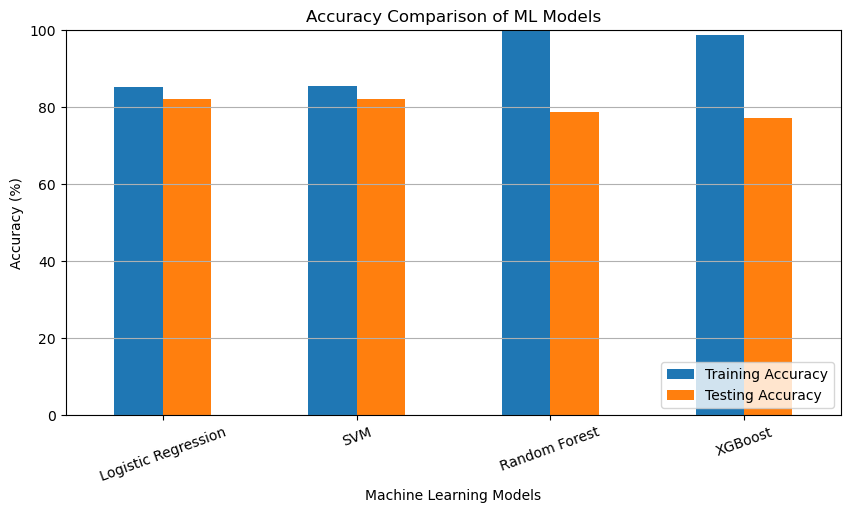

In [115]:
accuracy_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Accuracy Comparison of ML Models')
plt.ylabel('Accuracy (%)')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()